# 02 - Exploratory Data Analysis (PhishGuard)
**Owner:** Esar Fatima | **Inputs:** `data/cleaned.csv` (from Ayesha; falls back to the raw PhiUSIIL CSV until it's ready) | **Outputs:** plots in `images/`

Scope: URL-only features, because those are what the primary models use. Each plot has a note underneath - write what *you* see, not generic text.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid", context="notebook")

ROOT = ".." if os.path.exists("../data/cleaned.csv") else "."
os.makedirs(f"{ROOT}/images", exist_ok=True)

DATA_PATH = f"{ROOT}/data/cleaned.csv"
print("Loading:", DATA_PATH)
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head(3)

Loading: ../data/cleaned.csv
(235370, 26)


,URL,Domain,URLLength,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,is_phishing
0,https://www.southbankmosaics.com,www.southbankmosaics.com,31,24,0,com,100.0,1.000000,0.522907,0.061933,...,0.581,0,0.0,0,0,0,1,0.032,1,0
1,https://www.uni-mainz.de,www.uni-mainz.de,23,16,0,de,100.0,0.666667,0.032650,0.050207,...,0.391,0,0.0,0,0,0,2,0.087,1,0
2,https://www.voicefmradio.co.uk,www.voicefmradio.co.uk,29,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0.517,0,0.0,0,0,0,2,0.069,1,0


In [4]:
# In cleaned.csv: is_phishing = 1 means PHISHING, 0 means LEGITIMATE (opposite of the raw 'label')
df["class"] = df["is_phishing"].map({1: "Phishing", 0: "Legitimate"})
PALETTE = {"Phishing": "#d62728", "Legitimate": "#1f77b4"}

URL_FEATURES = [
    "URLLength", "DomainLength", "IsDomainIP", "URLSimilarityIndex", "CharContinuationRate",
    "TLDLegitimateProb", "URLCharProb", "TLDLength", "NoOfSubDomain", "HasObfuscation",
    "NoOfObfuscatedChar", "ObfuscationRatio", "NoOfLettersInURL", "LetterRatioInURL",
    "DegitRatioInURL" if False else "NoOfDegitsInURL", "DegitRatioInURL", "NoOfEqualsInURL",
    "NoOfQMarkInURL", "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL", "IsHTTPS",
]
URL_FEATURES = [c for c in URL_FEATURES if c in df.columns]
print(len(URL_FEATURES), "URL-only features available")
print(df[URL_FEATURES].isna().sum().sum(), "missing values in URL features")

22 URL-only features available
0 missing values in URL features


## 1. Class balance

             count  percent
class                      
Legitimate  134850    57.29
Phishing    100520    42.71


C:\Users\esaar\AppData\Local\Temp\ipykernel_23516\3901217466.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="class", order=["Legitimate", "Phishing"], palette=PALETTE, ax=ax)


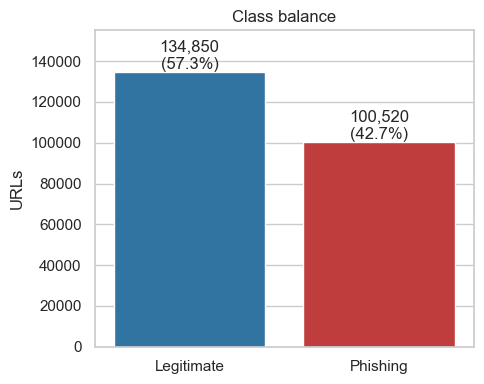

In [5]:
counts = df["class"].value_counts()
pct = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="class", order=["Legitimate", "Phishing"], palette=PALETTE, ax=ax)
for p, c in zip(ax.patches, counts[["Legitimate", "Phishing"]]):
    ax.annotate(f"{c:,}\n({c/len(df)*100:.1f}%)", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Class balance"); ax.set_ylabel("URLs"); ax.set_xlabel("")
ax.set_ylim(0, counts.max()*1.15)
plt.tight_layout(); plt.savefig("images/01_class_balance.png", dpi=200); plt.show()

**Note:** _Write 2-3 lines: the ratio, why it is only mildly imbalanced (so we still report Phishing recall/F1 + Macro F1, not accuracy), and whether class weighting is needed._

## 2. Feature distributions by class

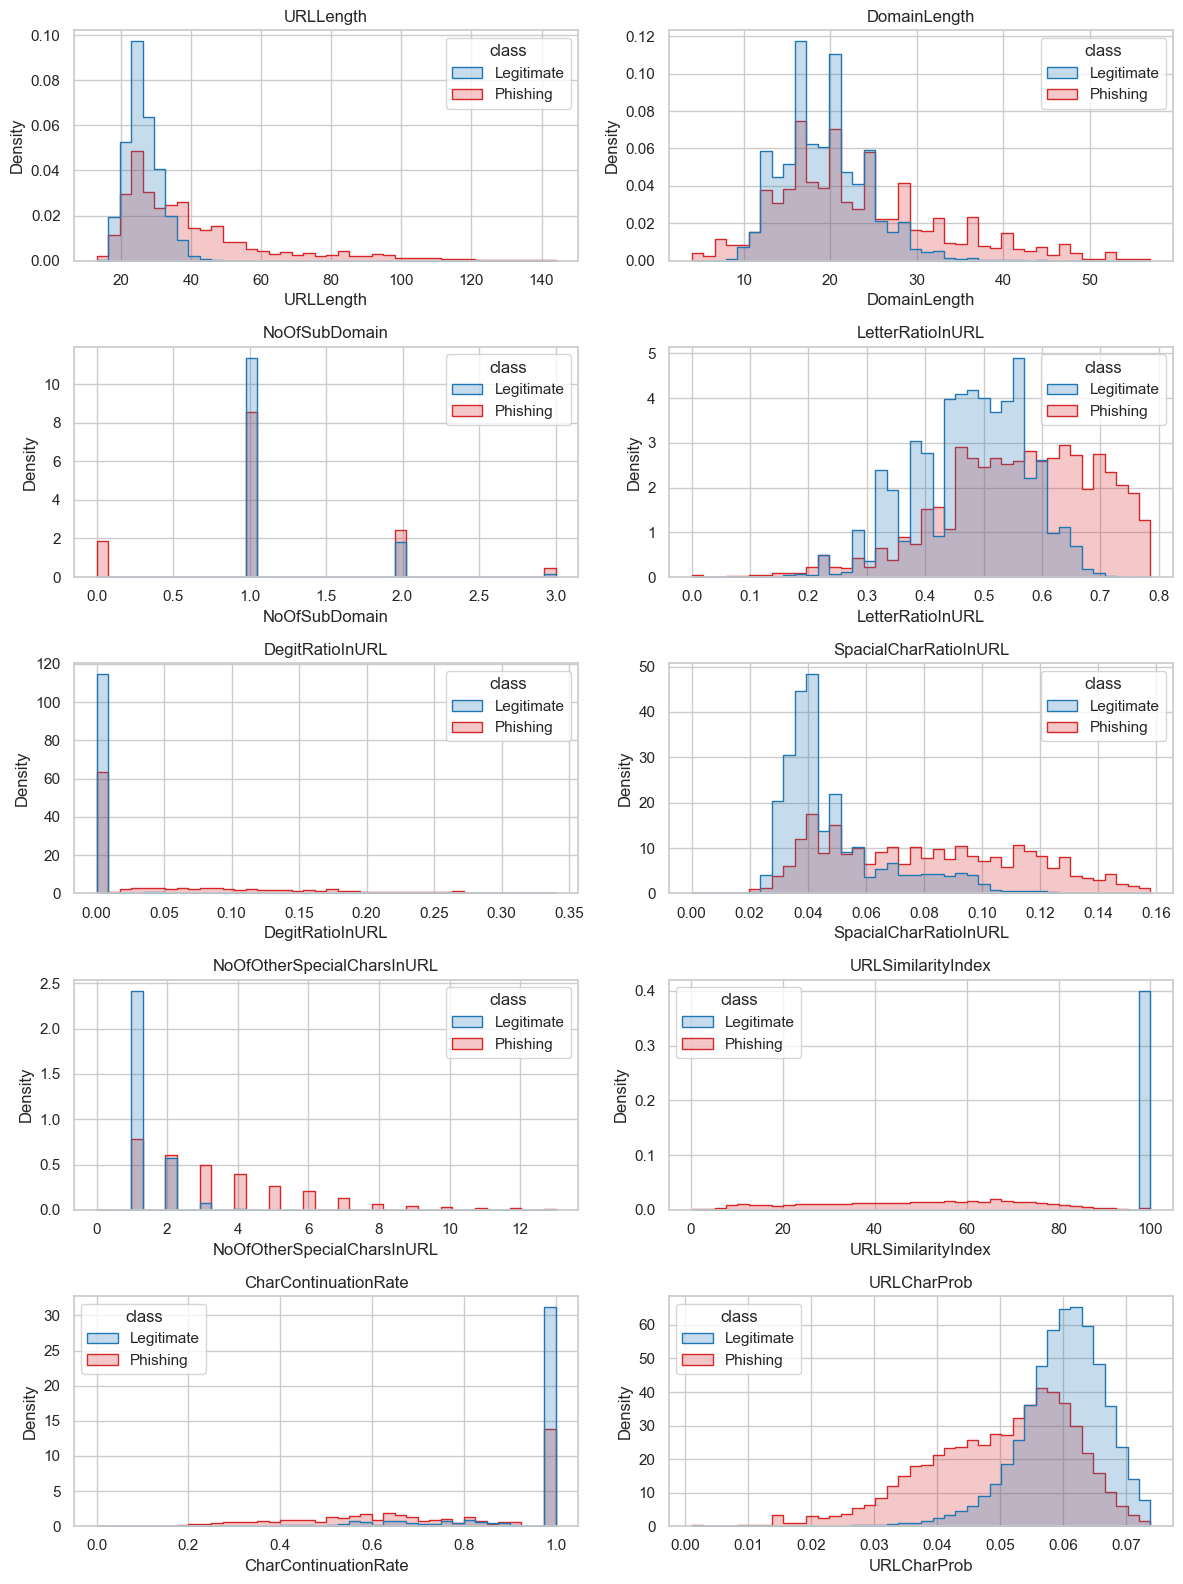

In [6]:
DIST_FEATURES = [f for f in ["URLLength", "DomainLength", "NoOfSubDomain", "LetterRatioInURL",
                 "DegitRatioInURL", "SpacialCharRatioInURL", "NoOfOtherSpecialCharsInURL",
                 "URLSimilarityIndex", "CharContinuationRate", "URLCharProb"] if f in df.columns]

ncols = 2
nrows = int(np.ceil(len(DIST_FEATURES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2*nrows))
for ax, f in zip(axes.ravel(), DIST_FEATURES):
    hi = df[f].quantile(0.99)                       # clip the extreme tail so the shape is visible
    sns.histplot(data=df[df[f] <= hi], x=f, hue="class", palette=PALETTE, bins=40,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f)
for ax in axes.ravel()[len(DIST_FEATURES):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("images/02_distributions.png", dpi=200); plt.show()

**Note:** _For each feature that separates the classes visibly, say how (e.g. phishing URLs are longer / have more special characters). Mention that the plots are clipped at the 99th percentile. Flag any feature where the two classes barely overlap - that is suspicious (see section 5)._

## 3. Boxplots by class

C:\Users\esaar\AppData\Local\Temp\ipykernel_23516\2842908482.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="class", y=f, order=["Legitimate", "Phishing"], palette=PALETTE,
C:\Users\esaar\AppData\Local\Temp\ipykernel_23516\2842908482.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="class", y=f, order=["Legitimate", "Phishing"], palette=PALETTE,
C:\Users\esaar\AppData\Local\Temp\ipykernel_23516\2842908482.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="class", y=f, order=["Legitimate", "Phishing"

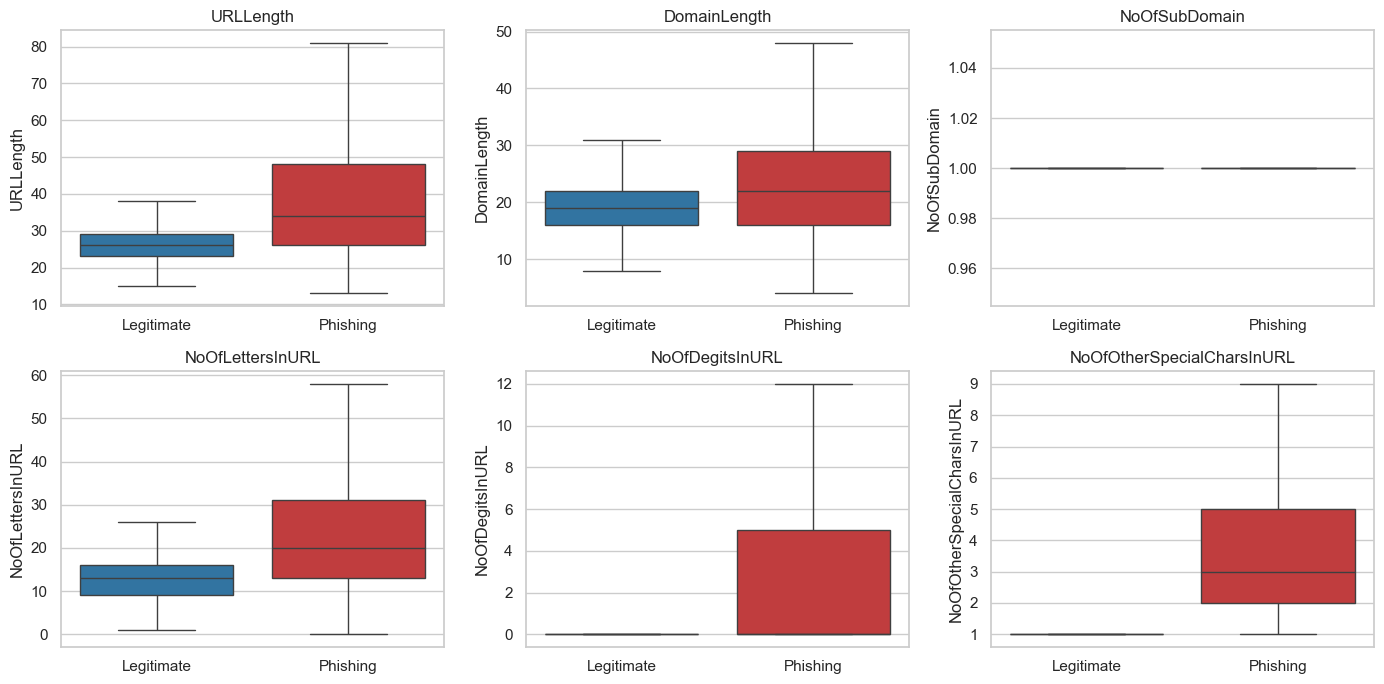

% of rows outside 1.5*IQR:
URLLength                      9.50
DomainLength                   5.68
NoOfSubDomain                 24.31
NoOfLettersInURL               8.30
NoOfDegitsInURL               21.75
NoOfOtherSpecialCharsInURL     5.23
dtype: float64


In [7]:
BOX_FEATURES = [f for f in ["URLLength", "DomainLength", "NoOfSubDomain", "NoOfLettersInURL",
                "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL"] if f in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), BOX_FEATURES):
    sns.boxplot(data=df, x="class", y=f, order=["Legitimate", "Phishing"], palette=PALETTE,
                showfliers=False, ax=ax)
    ax.set_title(f); ax.set_xlabel("")
for ax in axes.ravel()[len(BOX_FEATURES):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("images/03_boxplots.png", dpi=200); plt.show()

# how many outliers are hidden? (IQR rule, per feature)
q1, q3 = df[BOX_FEATURES].quantile(0.25), df[BOX_FEATURES].quantile(0.75)
iqr = q3 - q1
out_pct = ((df[BOX_FEATURES] > q3 + 1.5*iqr) | (df[BOX_FEATURES] < q1 - 1.5*iqr)).mean().mul(100).round(2)
print("% of rows outside 1.5*IQR:"); print(out_pct)

**Note:** _Compare medians and spread between classes. State that fliers are hidden for readability and quote the outlier percentages above. Tell Ayesha if outliers look like genuine long phishing URLs (keep) or data errors (cap)._

## 4. Correlation heatmap

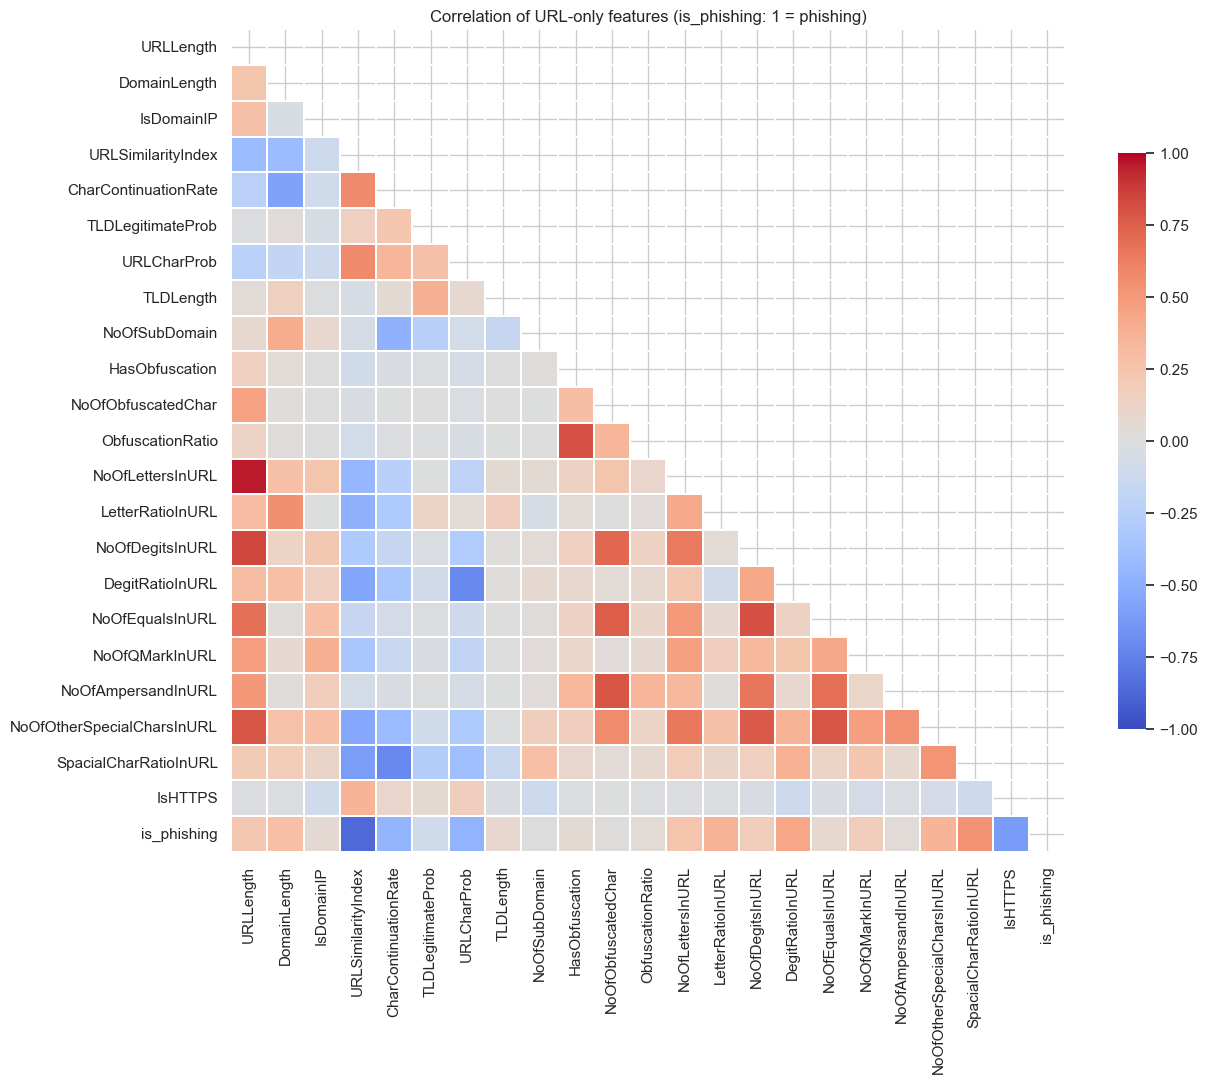

Correlation with is_phishing (sorted by |r|):
URLSimilarityIndex           -0.860
IsHTTPS                      -0.614
SpacialCharRatioInURL         0.533
URLCharProb                  -0.470
CharContinuationRate         -0.467
DegitRatioInURL               0.432
LetterRatioInURL              0.367
NoOfOtherSpecialCharsInURL    0.358
DomainLength                  0.283
NoOfLettersInURL              0.258
Name: is_phishing, dtype: float64

Highly correlated feature pairs (|r| > 0.85):
NoOfLettersInURL  URLLength             0.956
is_phishing       URLSimilarityIndex   -0.860
dtype: float64


In [9]:
corr = df[URL_FEATURES + ["is_phishing"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation of URL-only features (is_phishing: 1 = phishing)")
plt.tight_layout(); plt.savefig("../images/04_correlation_heatmap.png", dpi=200); plt.show()

print("Correlation with is_phishing (sorted by |r|):")
print(corr["is_phishing"].drop("is_phishing").sort_values(key=abs, ascending=False).round(3).head(10))

pairs = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack()
print("\nHighly correlated feature pairs (|r| > 0.85):")
print(pairs[pairs.abs() > 0.85].sort_values(key=abs, ascending=False).round(3))

**Note:** _Name the strongest correlates of the label, and the redundant pairs (e.g. count vs. ratio features, or length vs. letter counts). Say what this means for Logistic Regression (multicollinearity) vs. tree models (mostly unaffected)._

## 5. Extra checks that feed the rest of the project

                   feature  single_feature_AUC
        URLSimilarityIndex               0.996
NoOfOtherSpecialCharsInURL               0.823
     SpacialCharRatioInURL               0.807
               URLCharProb               0.768
                   IsHTTPS               0.757
      CharContinuationRate               0.743
          NoOfLettersInURL               0.742
                 URLLength               0.732
           NoOfDegitsInURL               0.728
           DegitRatioInURL               0.726
          LetterRatioInURL               0.715
              DomainLength               0.624
         TLDLegitimateProb               0.609
            NoOfQMarkInURL               0.530
           NoOfEqualsInURL               0.527
                 TLDLength               0.526
             NoOfSubDomain               0.514
        NoOfAmpersandInURL               0.504
                IsDomainIP               0.503
            HasObfuscation               0.502
        NoOfO

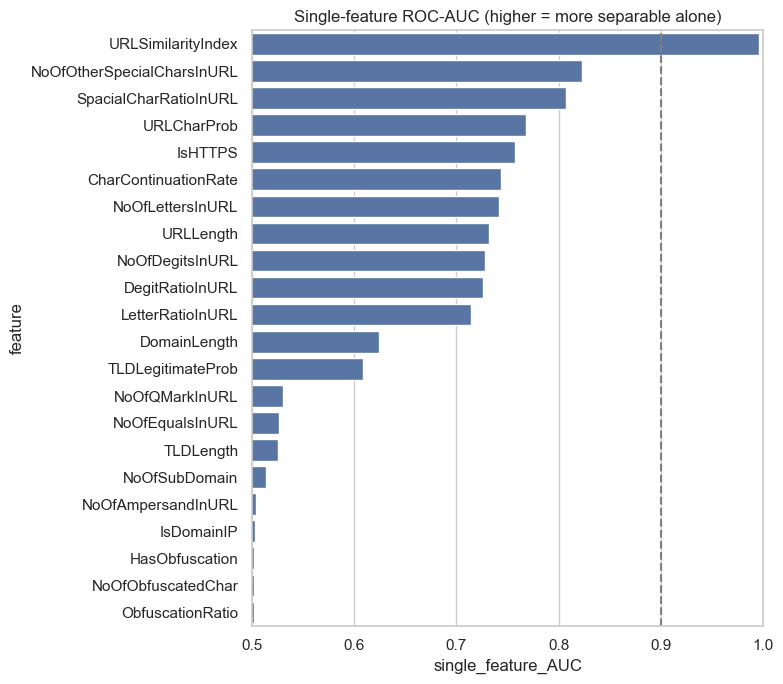

In [11]:
# (a) Single-feature separability: which features alone almost solve the task?
rows = []
for f in URL_FEATURES:
    auc = roc_auc_score(df["is_phishing"], df[f].fillna(df[f].median()))
    rows.append((f, max(auc, 1-auc)))
sep = pd.DataFrame(rows, columns=["feature", "single_feature_AUC"]).sort_values("single_feature_AUC", ascending=False)
print(sep.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=sep, y="feature", x="single_feature_AUC", color="#4c72b0", ax=ax)
ax.axvline(0.9, ls="--", c="grey"); ax.set_xlim(0.5, 1.0)
ax.set_title("Single-feature ROC-AUC (higher = more separable alone)")
plt.tight_layout(); plt.savefig("../images/05_single_feature_auc.png", dpi=200); plt.show()

In [13]:
# (b) Domain/TLD overlap - motivates the domain-disjoint split (handoff to Umaima)
if "Domain" in df.columns:
    dom = df.groupby("Domain")["is_phishing"].agg(["count", "nunique"])
    print("Unique domains:", len(dom), "of", len(df), "rows")
    print("Domains that appear with BOTH classes:", int((dom["nunique"] > 1).sum()))
    print("Rows from domains that appear more than once:",
          f"{dom[dom['count']>1]['count'].sum()/len(df)*100:.1f}%")
    print(dom.sort_values("count", ascending=False).head(10))
if "TLD" in df.columns:
    top = df["TLD"].value_counts().head(10).index
    print(pd.crosstab(df[df["TLD"].isin(top)]["TLD"], df["class"], normalize="index").round(3))

Unique domains: 220086 of 235370 rows
Domains that appear with BOTH classes: 54
Rows from domains that appear more than once: 8.7%
                              count  nunique
Domain                                      
ipfs.io                        1192        1
docs.google.com                 526        1
mail.deliverylifesupport.com    370        1
cloudflare-ipfs.com             359        1
storageapi.fleek.co             318        1
gateway.pinata.cloud            275        1
gateway.ipfs.io                 249        1
ipfs.litnet.work                223        1
cf-ipfs.com                     190        1
s3.amazonaws.com                182        1
class  Legitimate  Phishing
TLD                        
app         0.022     0.978
au          0.875     0.125
co          0.085     0.915
com         0.612     0.388
de          0.829     0.171
io          0.103     0.897
net         0.565     0.435
org         0.879     0.121
ru          0.230     0.770
uk          0.950    

**Note:** _Features with single-feature AUC near 1.0 (typically URLSimilarityIndex, URLCharProb, TLDLegitimateProb) can dominate and may reflect how the dataset was built rather than real phishing signal - this is exactly what the ablation study tests. Also report how many domains repeat across rows: that is the evidence for why a random split can leak domains._

## Summary of findings

1. **Class balance:** 134,850 legitimate (57.3%) and 100,520 phishing (42.7%), 235,370 URLs in total. The imbalance is mild (about 1.34 : 1), so no resampling is needed. We will use stratified splits and report phishing recall, F1, macro-F1 and PR-AUC instead of accuracy. The proposal's 100,945 phishing URLs became 100,520 because 425 duplicate phishing URLs were removed during cleaning.

2. **Most discriminative features:** URLSimilarityIndex is by far the strongest (single-feature AUC 0.996, Pearson r = -0.86 with is_phishing). The next are NoOfOtherSpecialCharsInURL (0.823), SpacialCharRatioInURL (0.807), URLCharProb (0.768), IsHTTPS (0.757) and CharContinuationRate (0.743). Phishing URLs are longer (median URLLength about 34 vs 26) and contain more digits and special characters, while legitimate URLs concentrate tightly around short, letter-dominated forms. Obfuscation flags, IsDomainIP, NoOfAmpersandInURL and NoOfSubDomain have AUC near 0.50, so they carry little signal alone, although they are rare.

3. **Redundant / highly correlated features:** At |r| > 0.85 the only feature pair is NoOfLettersInURL and URLLength (0.956). The heatmap also shows families that move together: the count features (letters, digits, equals signs, special characters) all track URLLength, and HasObfuscation, NoOfObfuscatedChar and ObfuscationRatio are near-duplicates (all AUC 0.502). For the models, keep one or two per family, and expect the logistic regression coefficients to be unstable and the ablation to show little change when one member of a family is removed. NoOfSubDomain and NoOfDegitsInURL show 24.3% and 21.8% IQR outliers only because the IQR is almost zero, so those percentages are an artefact and not real extreme values.

4. **Suspiciously strong features (ablation candidates):** URLSimilarityIndex is the main one (AUC 0.996; legitimate URLs sit at exactly 100 while phishing spreads from 0 to 100). It is computed relative to the dataset's own URLs, so it may encode the data collection and not phishing behaviour. IsHTTPS, URLCharProb and TLDLegitimateProb are also suspects. Models should be reported with and without these features, and as the proposal says, the ablation should remove the similarity-style and TLD groups in turn.

5. **Domain repetition and why it matters for the split:** There are 220,086 unique domains across 235,370 rows, and 8.7% of rows belong to a domain that appears more than once. The repeats are concentrated in hosting and file-sharing platforms that attackers abuse, such as ipfs.io (1,192 rows), docs.google.com (526), cloudflare-ipfs.com, gateway.pinata.cloud and s3.amazonaws.com. 54 domains appear with both classes. A random split places the same domain in train and test, so the model can memorize domains. TLD is also strongly skewed: .app, .co, .io and .ru are mostly phishing, while .uk, .org, .au and .de are mostly legitimate. This motivates the domain-disjoint split, and Umaima needs to decide where the 54 mixed-class domains go.